# Demo 2 — Relationships between distributions

**Day 2 · Bayesian statistics · Aalborg University 2026** · shown in Lecture B (afternoon)

This notebook follows the slides **"Relationships between distributions"**, one section per slide. It is for orientation: **you do not need to memorise these connections**.

Each section checks one connection by simulation. In every plot the **grey bars** are simulated values and the **black points or line** are the exact distribution. If they agree, the connection holds.

R only, no Stan.

**R used in this notebook.** `tibble()` makes a small table; `|>` reads as "and then"; `mutate()` adds a column; `bind_rows()` stacks tables on top of each other; `count(k)` counts how often each value of `k` occurs. Everything else is base R: `dbeta`, `qbeta`, `pbeta`, `rbeta` (and the same for `binom`, `pois`, `gamma`).

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # tibble, dplyr and ggplot2
set.seed(2026)
theme_set(theme_minimal(base_size = 13))
n_sim <- 100000   # number of simulated values in each check

## 1. Bernoulli → binomial: add up the trials

*Slide: Binomial(n, p), "add up n independent Bernoulli(p) trials".*

One departure is on time (1) with probability p = 0.7, late (0) otherwise: a **Bernoulli(0.7)** trial. Add up 20 such trials and you get the number on time out of 20, which is **Binomial(20, 0.7)**.

We simulate 20 trials, add them up, and repeat this many times.

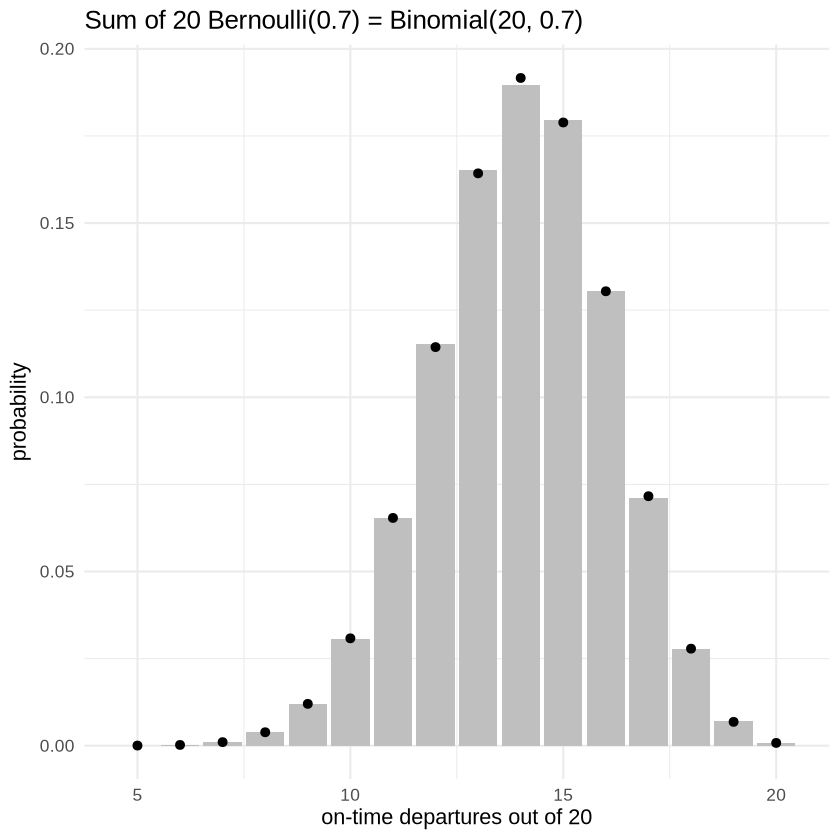

In [2]:
# rbinom(20, size = 1, prob = 0.7) gives 20 Bernoulli trials; sum() adds them up;
# replicate() repeats this n_sim times
totals <- replicate(n_sim, sum(rbinom(20, size = 1, prob = 0.7)))

tibble(k = totals) |>
  count(k) |>
  mutate(simulated = n / n_sim,                 # share of simulations with this total
         exact     = dbinom(k, 20, 0.7)) |>     # Binomial(20, 0.7)
  ggplot(aes(x = k)) +
  geom_col(aes(y = simulated), fill = "grey75") +
  geom_point(aes(y = exact), size = 2) +
  labs(x = "on-time departures out of 20", y = "probability",
       title = "Sum of 20 Bernoulli(0.7) = Binomial(20, 0.7)")

## 2. Binomial → Poisson: many short time slices

*Slides: "Counting things: from binomial to Poisson" and Poisson(λ), "λ = 2 bikes per minute".*

Bikes pass a counter at about λ = 2 per minute. Cut one minute into m slices. In each slice a bike passes or not, with probability p = 2/m, so the count in the minute is **Binomial(m, 2/m)**. The more slices, the closer this gets to **Poisson(2)**.

We compare 4 slices, 10 slices and 1000 slices.

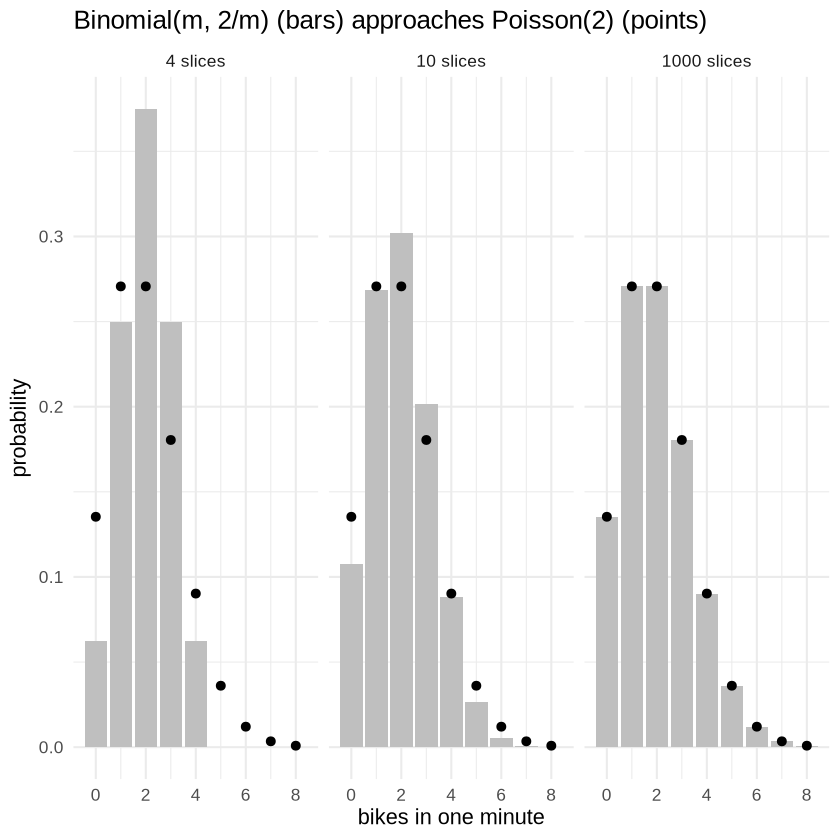

In [3]:
lambda <- 2
k <- 0:8

slices <- bind_rows(
  tibble(k = k, binomial = dbinom(k, 4,    lambda / 4),    m = "4 slices"),
  tibble(k = k, binomial = dbinom(k, 10,   lambda / 10),   m = "10 slices"),
  tibble(k = k, binomial = dbinom(k, 1000, lambda / 1000), m = "1000 slices")
) |>
  mutate(poisson = dpois(k, lambda),
         m = factor(m, levels = c("4 slices", "10 slices", "1000 slices")))   # panel order

ggplot(slices, aes(x = k)) +
  geom_col(aes(y = binomial), fill = "grey75") +
  geom_point(aes(y = poisson), size = 2) +
  facet_wrap(~ m) +
  labs(x = "bikes in one minute", y = "probability",
       title = "Binomial(m, 2/m) (bars) approaches Poisson(2) (points)")

## 3. Binomial → normal: the central limit theorem

*Slide: Normal(μ, σ²), "the central limit theorem".*

For large n, Binomial(n, p) is close to a normal distribution with the same mean μ = np and variance σ² = np(1 − p).

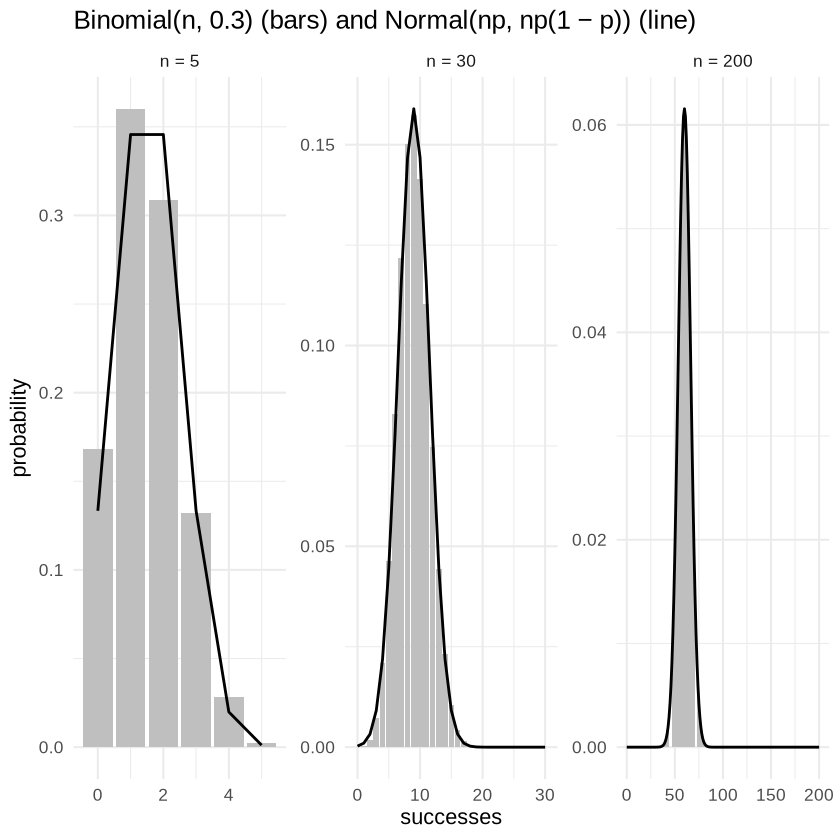

In [4]:
p <- 0.3
binom_normal <- bind_rows(
  tibble(n = 5,   k = 0:5),
  tibble(n = 30,  k = 0:30),
  tibble(n = 200, k = 0:200)
) |>
  mutate(binomial = dbinom(k, n, p),
         normal   = dnorm(k, mean = n * p, sd = sqrt(n * p * (1 - p))),
         panel    = factor(paste("n =", n), levels = c("n = 5", "n = 30", "n = 200")))

ggplot(binom_normal, aes(x = k)) +
  geom_col(aes(y = binomial), fill = "grey75") +
  geom_line(aes(y = normal), linewidth = 0.8) +
  facet_wrap(~ panel, scales = "free") +
  labs(x = "successes", y = "probability",
       title = "Binomial(n, 0.3) (bars) and Normal(np, np(1 − p)) (line)")

## 4. Poisson counts ↔ exponential waiting times

*Slide: Exponential(λ), "the same bikes, timed instead of counted".*

The key line on the slide: **you wait longer than t minutes ⇔ 0 bikes pass in those t minutes.**

- Poisson side: the count in t minutes is Poisson(λt), so P(0 bikes) = e^(−λt).
- Exponential side: the waiting time to the next bike is Exponential(λ), so P(wait > t) = e^(−λt).

We simulate many waiting times and check both numbers for t = 0.5 and t = 1 minute.

In [5]:
waits <- rexp(n_sim, rate = lambda)    # simulated waiting times to the next bike, in minutes

t <- 0.5
c(simulated_P_wait_longer = mean(waits > t),        # share of waits longer than t
  poisson_P_zero_bikes    = dpois(0, lambda * t),   # P(0 bikes in t minutes)
  formula                 = exp(-lambda * t))

t <- 1
c(simulated_P_wait_longer = mean(waits > t),
  poisson_P_zero_bikes    = dpois(0, lambda * t),
  formula                 = exp(-lambda * t))

simulated_P_wait_longer    poisson_P_zero_bikes                 formula 
              0.3681000               0.3678794               0.3678794

simulated_P_wait_longer    poisson_P_zero_bikes                 formula 
              0.1365200               0.1353353               0.1353353

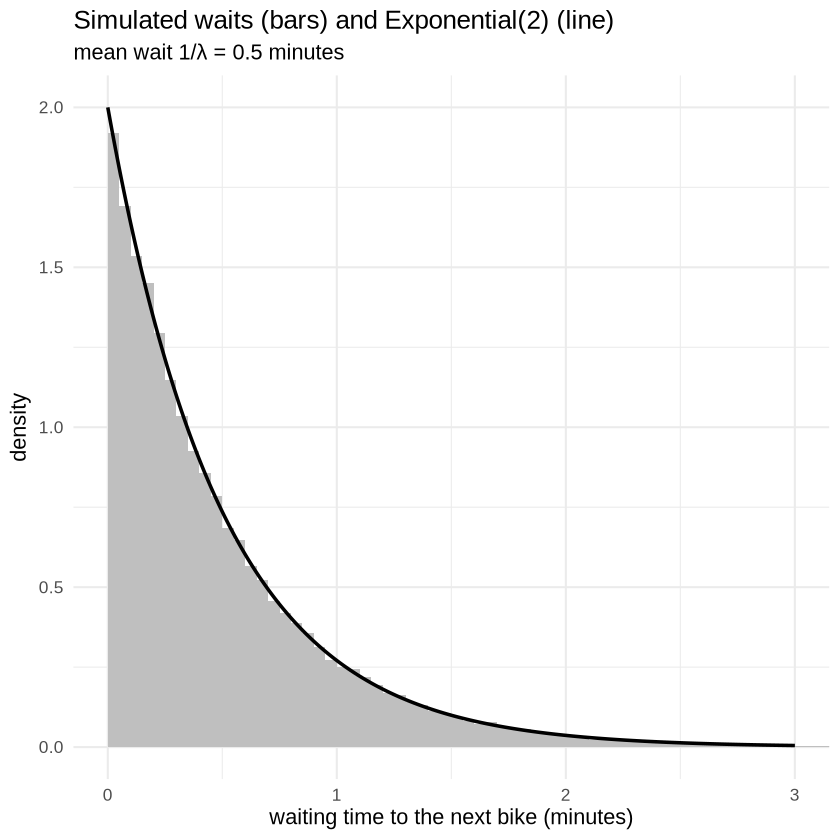

In [6]:
wait_grid <- seq(0, 3, length.out = 301)
exp_curve <- tibble(wait = wait_grid, density = dexp(wait_grid, rate = lambda))

ggplot(tibble(wait = waits), aes(x = wait)) +
  geom_histogram(aes(y = after_stat(density)), binwidth = 0.05, boundary = 0, fill = "grey75") +
  geom_line(data = exp_curve, aes(x = wait, y = density), linewidth = 1) +
  coord_cartesian(xlim = c(0, 3)) +
  labs(x = "waiting time to the next bike (minutes)", y = "density",
       title = "Simulated waits (bars) and Exponential(2) (line)",
       subtitle = "mean wait 1/λ = 0.5 minutes")

## 5. Counts over t minutes: why exposure works

*Slide: Exponential(λ), last card "Counts over t minutes"; and "Exposure: counts over different lengths of time".*

Counting for 10 minutes is the same as adding ten one-minute counts. Adding up ten Poisson(2) counts gives **Poisson(10 × 2) = Poisson(20)**. In general a count over t minutes is Poisson(λ t).

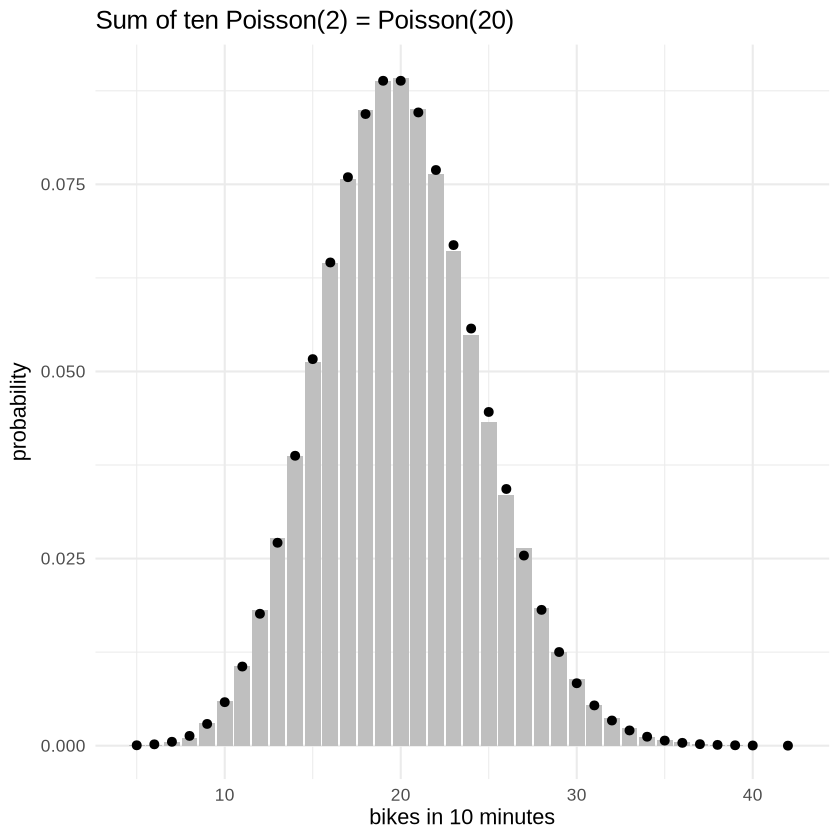

In [7]:
ten_minutes <- replicate(n_sim, sum(rpois(10, lambda)))   # ten one-minute counts, added up

tibble(k = ten_minutes) |>
  count(k) |>
  mutate(simulated = n / n_sim,
         exact     = dpois(k, 10 * lambda)) |>
  ggplot(aes(x = k)) +
  geom_col(aes(y = simulated), fill = "grey75") +
  geom_point(aes(y = exact), size = 2) +
  labs(x = "bikes in 10 minutes", y = "probability", title = "Sum of ten Poisson(2) = Poisson(20)")

## 6. When the rate itself is uncertain → negative binomial

*Slide: "When the parameter itself is uncertain"; also Exercise B2.*

If we are not sure about λ, we draw it from a distribution first (here Gamma(20, 10), mean 2 per minute) and then draw a Poisson count for t = 5 minutes, exactly the two steps of a prediction. The counts are **more spread out** than a Poisson with λ fixed at 2.

The exact distribution of these counts is called **negative binomial**. In R: `dnbinom(k, size = a, prob = b / (b + t))` for a Gamma(a, b) rate. You do not need to remember this formula.

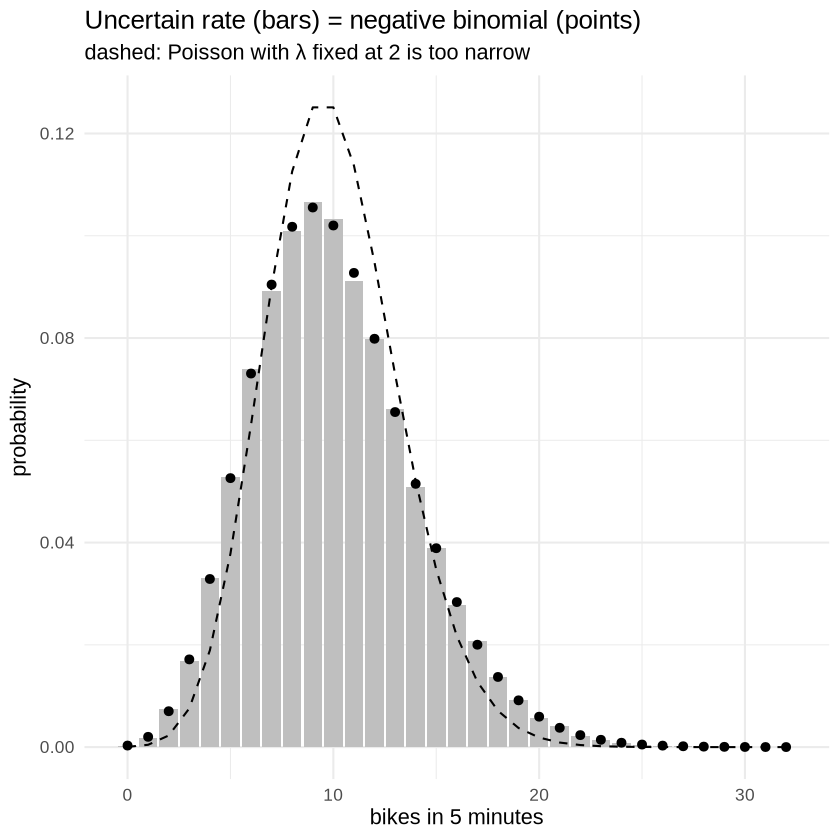

In [8]:
a_g <- 20; b_g <- 10; t <- 5                       # rate ~ Gamma(20, 10); 5-minute window

rate_draws <- rgamma(n_sim, shape = a_g, rate = b_g)   # step 1: an uncertain rate
counts     <- rpois(n_sim, lambda = rate_draws * t)    # step 2: a count given that rate

tibble(k = counts) |>
  count(k) |>
  mutate(simulated = n / n_sim,
         neg_binom = dnbinom(k, size = a_g, prob = b_g / (b_g + t)),   # exact
         poisson   = dpois(k, 2 * t)) |>                               # if λ were exactly 2
  ggplot(aes(x = k)) +
  geom_col(aes(y = simulated), fill = "grey75") +
  geom_point(aes(y = neg_binom), size = 2) +
  geom_line(aes(y = poisson), linetype = "dashed") +
  labs(x = "bikes in 5 minutes", y = "probability",
       title = "Uncertain rate (bars) = negative binomial (points)",
       subtitle = "dashed: Poisson with λ fixed at 2 is too narrow")

In [9]:
c(variance_uncertain_rate = var(counts),   # wider
  variance_poisson_fixed  = 2 * t)         # Poisson: variance = mean = 10

variance_uncertain_rate  variance_poisson_fixed 
               15.01355                10.00000

## 7. When the probability itself is uncertain → beta-binomial

*Slides: "When the parameter itself is uncertain" and "Predicting the next 10 departures".*

The same idea for proportions: draw θ from Beta(16, 8) (this morning's posterior), then draw the number on time among the next 10 departures. The result, called **beta-binomial**, is wider than a binomial with θ fixed at its mean 0.667.

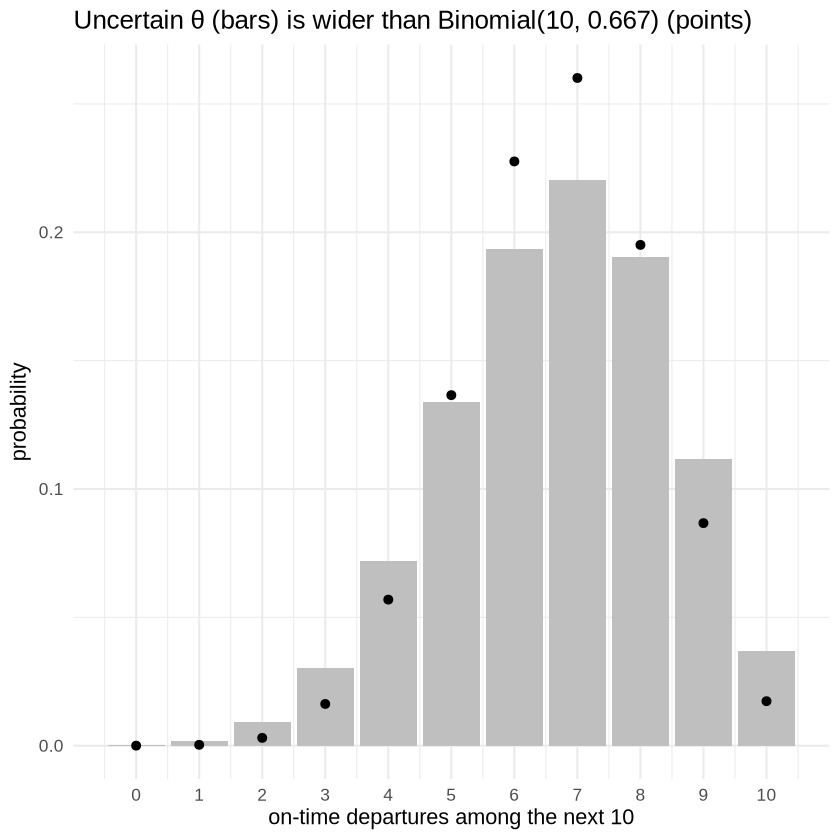

In [10]:
theta_draws <- rbeta(n_sim, 16, 8)                 # step 1: an uncertain θ
next10      <- rbinom(n_sim, 10, theta_draws)      # step 2: next 10 departures given θ

tibble(k = next10) |>
  count(k) |>
  mutate(simulated = n / n_sim,
         binomial  = dbinom(k, 10, 16 / 24)) |>    # if θ were exactly 0.667
  ggplot(aes(x = k)) +
  geom_col(aes(y = simulated), fill = "grey75") +
  geom_point(aes(y = binomial), size = 2) +
  scale_x_continuous(breaks = 0:10) +
  labs(x = "on-time departures among the next 10", y = "probability",
       title = "Uncertain θ (bars) is wider than Binomial(10, 0.667) (points)")

## 8. Beta(1, 1) is the uniform distribution

*Slide: "Putting it together" (the arrow "a = b = 1").*

The flat prior for a proportion is a beta distribution with a = b = 1: every value between 0 and 1 is equally likely.

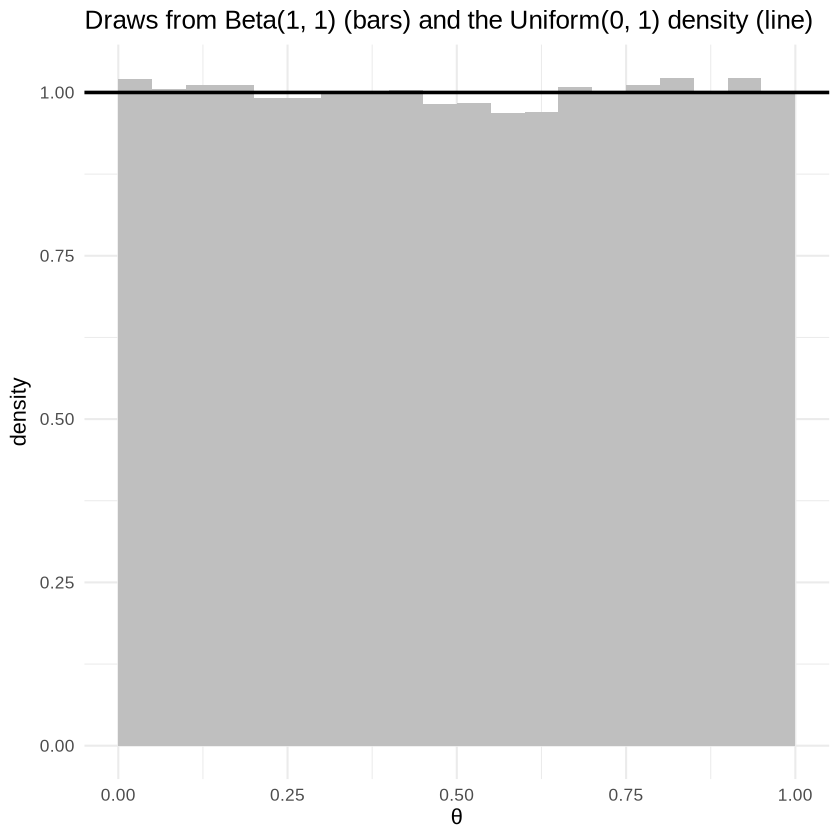

In [11]:
ggplot(tibble(theta = rbeta(n_sim, 1, 1)), aes(x = theta)) +
  geom_histogram(aes(y = after_stat(density)), breaks = seq(0, 1, 0.05), fill = "grey75") +
  geom_hline(yintercept = 1, linewidth = 1) +     # the Uniform(0, 1) density is 1 everywhere
  labs(x = "θ", y = "density", title = "Draws from Beta(1, 1) (bars) and the Uniform(0, 1) density (line)")

## Summary

| From | To | How | Section |
|---|---|---|---|
| Bernoulli(p) | Binomial(n, p) | add up n independent trials | 1 |
| Binomial(n, p) | Poisson(λ) | many slices: n → ∞, p = λ/n | 2 |
| Binomial(n, p) | Normal(np, np(1 − p)) | n large (central limit theorem) | 3 |
| Poisson(λ) counts | Exponential(λ) waiting times | wait > t ⇔ 0 events in t | 4 |
| Poisson(λ) + … + Poisson(λ) | Poisson(λ t) | counts over t minutes: exposure | 5 |
| Poisson(λ t), λ uncertain (gamma) | negative binomial | today's predictive for counts | 6 |
| Binomial(n, θ), θ uncertain (beta) | beta-binomial | today's predictive for proportions | 7 |
| Beta(1, 1) | Uniform(0, 1) | the same distribution | 8 |